In [3]:
# Install dependencies
!pip install -q datasets tokenizers matplotlib pandas numpy tqdm

# Import libraries
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from datasets import load_dataset
from collections import Counter

# Reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:",
          round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2),
          "GB")


Device: cuda
GPU: Tesla T4
VRAM: 15.64 GB


In [4]:
# Load a small sample first
dataset = load_dataset(
    "roneneldan/TinyStories",
    split="train[:1000]"
)

print("Number of stories:", len(dataset))
print("\nFirst example:\n")
print(dataset[0]["text"])

# Basic statistics
lengths = [len(example["text"]) for example in dataset]

print("\nDataset statistics")
print("Average characters:", np.mean(lengths))
print("Median characters:", np.median(lengths))
print("Maximum characters:", np.max(lengths))


README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

data/train-00000-of-00004-2d5a1467fff108(…): reconstructing file:   0%|          |  0.00B /  249MB            

data/train-00000-of-00004-2d5a1467fff108(…): downloading bytes:           |  0.00B            

data/train-00001-of-00004-5852b56a2bd28f(…): reconstructing file:   0%|          |  0.00B /  248MB            

data/train-00001-of-00004-5852b56a2bd28f(…): downloading bytes:           |  0.00B            

data/train-00002-of-00004-a26307300439e9(…): reconstructing file:   0%|          |  0.00B /  246MB            

... (4 outputs left out)

data/validation-00000-of-00001-869c898b5(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2119719 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/21990 [00:00<?, ? examples/s]

Number of stories: 1000

First example:

One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she could sew a button on her shirt.

Lily went to her mom and said, "Mom, I found this needle. Can you share it with me and sew my shirt?" Her mom smiled and said, "Yes, Lily, we can share the needle and fix your shirt."

Together, they shared the needle and sewed the button on Lily's shirt. It was not difficult for them because they were sharing and helping each other. After they finished, Lily thanked her mom for sharing the needle and fixing her shirt. They both felt happy because they had shared and worked together.

Dataset statistics
Average characters: 941.64
Median characters: 814.0
Maximum characters: 4123


In [5]:
from datasets import load_dataset

SEED = 42

# Load the complete cached dataset
full_dataset = load_dataset("roneneldan/TinyStories")

# Reserve 10,000 stories for final testing
split = full_dataset["train"].train_test_split(
    test_size=10_000,
    seed=SEED
)

train_dataset = split["train"]
test_dataset = split["test"]
val_dataset = full_dataset["validation"]

print("Dataset split summary")
print("-" * 40)
print("Training stories:", len(train_dataset))
print("Validation stories:", len(val_dataset))
print("Test stories:", len(test_dataset))

print("\nTraining example:")
print(train_dataset[0]["text"][:500])

print("\nValidation example:")
print(val_dataset[0]["text"][:500])

print("\nTest example:")
print(test_dataset[0]["text"][:500])


Dataset split summary
----------------------------------------
Training stories: 2109719
Validation stories: 21990
Test stories: 10000

Training example:
Anna and Ben are twins. They like to play with their toys in their room. One day, they hear a loud noise from the bathroom. They run to see what it is.

"Oh no!" Anna says. "There is a leak in the sink! Water is everywhere!"

Ben sees a big hole in the pipe under the sink. He remembers what their dad told them. "We have to call the plumber. He can fix the leak. He is famous for fixing leaks."

Anna nods. She picks up the phone and dials the number. She waits for someone to answer.

"Hello, this 

Validation example:
Spot. Spot saw the shiny car and said, "Wow, Kitty, your car is so bright and clean!" Kitty smiled and replied, "Thank you, Spot. I polish it every day."

After playing with the car, Kitty and Spot felt thirsty. They found a small pond with clear water. They drank the water and felt very happy. They played together all day

In [6]:
!pip install -q tokenizers

from tokenizers import Tokenizer
from tokenizers.models import BPE
from tokenizers.trainers import BpeTrainer
from tokenizers.pre_tokenizers import ByteLevel
from tokenizers.decoders import ByteLevel as ByteLevelDecoder

import os

In [7]:
# Configuration
VOCAB_SIZE = 8000
TOKENIZER_SAMPLE_SIZE = 200_000
SEED = 42

# Select deterministic training subset
tokenizer_data = train_dataset.select(
    range(TOKENIZER_SAMPLE_SIZE)
)

# Initialise BPE tokenizer
tokenizer = Tokenizer(BPE(unk_token="[UNK]"))

# Byte-level pre-tokenisation
tokenizer.pre_tokenizer = ByteLevel(add_prefix_space=False)
tokenizer.decoder = ByteLevelDecoder()

# Define special tokens
trainer = BpeTrainer(
    vocab_size=VOCAB_SIZE,
    min_frequency=2,
    special_tokens=[
        "[UNK]",
        "[BOS]",
        "[EOS]",
        "[PAD]"
    ],
    initial_alphabet=ByteLevel.alphabet()
)

# Train using training stories only
def batch_iterator(batch_size=1000):
    for i in range(0, len(tokenizer_data), batch_size):
        yield tokenizer_data[i:i+batch_size]["text"]

tokenizer.train_from_iterator(
    batch_iterator(),
    trainer=trainer,
    length=len(tokenizer_data)
)

# Save tokenizer
os.makedirs("artifacts", exist_ok=True)
tokenizer.save("artifacts/tokenizer.json")

print("Tokenizer training completed!")
print("Vocabulary size:", tokenizer.get_vocab_size())

Tokenizer training completed!
Vocabulary size: 8000


In [8]:
sample_text = train_dataset[0]["text"]

encoded = tokenizer.encode(sample_text)

print("Original text:")
print(sample_text[:300])

print("\nToken IDs:")
print(encoded.ids[:50])

print("\nDecoded text:")
print(tokenizer.decode(encoded.ids)[:300])

print("\nNumber of tokens:", len(encoded.ids))
print("Vocabulary size:", tokenizer.get_vocab_size())

# Check special tokens
for token in ["[UNK]", "[BOS]", "[EOS]", "[PAD]"]:
    print(token, ":", tokenizer.token_to_id(token))

Original text:
Anna and Ben are twins. They like to play with their toys in their room. One day, they hear a loud noise from the bathroom. They run to see what it is.

"Oh no!" Anna says. "There is a leak in the sink! Water is everywhere!"

Ben sees a big hole in the pipe under the sink. He remembers what their da

Token IDs:
[1144, 268, 478, 443, 1784, 17, 323, 514, 269, 362, 345, 457, 674, 319, 457, 768, 17, 511, 359, 15, 365, 1423, 262, 868, 974, 580, 266, 2812, 17, 323, 722, 269, 518, 546, 307, 411, 17, 202, 202, 5, 1602, 497, 427, 767, 563, 17, 331, 2654, 411, 262]

Decoded text:
Anna and Ben are twins. They like to play with their toys in their room. One day, they hear a loud noise from the bathroom. They run to see what it is.

"Oh no!" Anna says. "There is a leak in the sink! Water is everywhere!"

Ben sees a big hole in the pipe under the sink. He remembers what their da

Number of tokens: 322
Vocabulary size: 8000
[UNK] : 0
[BOS] : 1
[EOS] : 2
[PAD] : 3


In [9]:
sample_text = train_dataset[0]["text"]

encoded = tokenizer.encode(sample_text)
decoded = tokenizer.decode(encoded.ids)

print("Exact reconstruction:", decoded == sample_text)
print("Original characters:", len(sample_text))
print("Encoded tokens:", len(encoded.ids))
print("Compression ratio:",
      round(len(sample_text) / len(encoded.ids), 2),
      "characters/token")

Exact reconstruction: True
Original characters: 1175
Encoded tokens: 322
Compression ratio: 3.65 characters/token


In [10]:
EOS_ID = tokenizer.token_to_id("[EOS]")
PAD_ID = tokenizer.token_to_id("[PAD]")
BOS_ID = tokenizer.token_to_id("[BOS]")

def encode_story(text):
    """
    Encode one story and append an EOS token.
    """
    ids = tokenizer.encode(text).ids
    ids.append(EOS_ID)
    return ids

# Test
sample_ids = encode_story(train_dataset[0]["text"])

print("First 30 IDs:", sample_ids[:30])
print("Last token:", sample_ids[-1])
print("EOS ID:", EOS_ID)

assert sample_ids[-1] == EOS_ID

First 30 IDs: [1144, 268, 478, 443, 1784, 17, 323, 514, 269, 362, 345, 457, 674, 319, 457, 768, 17, 511, 359, 15, 365, 1423, 262, 868, 974, 580, 266, 2812, 17, 323]
Last token: 2
EOS ID: 2


In [11]:
from tqdm.auto import tqdm
import numpy as np

PILOT_SIZE = 10_000

def tokenize_dataset(dataset):
    all_ids = []

    for example in tqdm(dataset):
        ids = encode_story(example["text"])
        all_ids.extend(ids)

    return np.array(all_ids, dtype=np.uint16)

# Pilot training dataset
pilot_train = train_dataset.select(range(PILOT_SIZE))

train_tokens = tokenize_dataset(pilot_train)
val_tokens = tokenize_dataset(val_dataset)

print("Training tokens:", len(train_tokens))
print("Validation tokens:", len(val_tokens))

print("Training memory:",
      round(train_tokens.nbytes / 1024**2, 2), "MB")

print("Validation memory:",
      round(val_tokens.nbytes / 1024**2, 2), "MB")

  0%|          | 0/10000 [00:00<?, ?it/s]

  0%|          | 0/21990 [00:00<?, ?it/s]

Training tokens: 2185263
Validation tokens: 4694253
Training memory: 4.17 MB
Validation memory: 8.95 MB


In [12]:
import os

os.makedirs("artifacts", exist_ok=True)

np.save("artifacts/train_tokens_pilot.npy", train_tokens)
np.save("artifacts/val_tokens.npy", val_tokens)

print("Tokenised datasets saved.")

Tokenised datasets saved.


In [13]:
import numpy as np
import torch

device = "cuda"

train_tokens = np.load(
    "artifacts/train_tokens_pilot.npy"
)

val_tokens = np.load(
    "artifacts/val_tokens.npy"
)

# Convert to PyTorch tensors
train_data = torch.from_numpy(
    train_tokens.astype(np.int64)
)

val_data = torch.from_numpy(
    val_tokens.astype(np.int64)
)

print("Training tensor:", train_data.shape)
print("Validation tensor:", val_data.shape)

Training tensor: torch.Size([2185263])
Validation tensor: torch.Size([4694253])


In [14]:
BLOCK_SIZE = 256
BATCH_SIZE = 32

def get_batch(data, batch_size=BATCH_SIZE):
    """
    Generate random batches for autoregressive
    next-token prediction.
    """

    ix = torch.randint(
        len(data) - BLOCK_SIZE - 1,
        (batch_size,)
    )

    offsets = torch.arange(BLOCK_SIZE)

    x = data[ix[:, None] + offsets]
    y = data[ix[:, None] + offsets + 1]

    return (
        x.to(device),
        y.to(device)
    )


# Test the batch generator
xb, yb = get_batch(train_data)

print("Input shape:", xb.shape)
print("Target shape:", yb.shape)
print("Input dtype:", xb.dtype)
print("Target dtype:", yb.dtype)
print("GPU device:", xb.device)

assert xb.shape == (BATCH_SIZE, BLOCK_SIZE)
assert yb.shape == (BATCH_SIZE, BLOCK_SIZE)
assert torch.equal(xb[:, 1:], yb[:, :-1])

Input shape: torch.Size([32, 256])
Target shape: torch.Size([32, 256])
Input dtype: torch.int64
Target dtype: torch.int64
GPU device: cuda:0


In [15]:
sample_x, sample_y = get_batch(
    train_data,
    batch_size=1
)

input_ids = sample_x[0].tolist()
target_ids = sample_y[0].tolist()

print("Input:")
print(tokenizer.decode(input_ids[:30]))

print("\nTarget:")
print(tokenizer.decode(target_ids[:30]))

Input:
 all kinds of flowers and trees. They built a bright fence, and strung up lights that made the backyard sparkle. There was also a trampoline and

Target:
 kinds of flowers and trees. They built a bright fence, and strung up lights that made the backyard sparkle. There was also a trampoline and sandbox


In [16]:
%%writefile model.py

import torch
import torch.nn as nn
import torch.nn.functional as F


class CausalSelfAttention(nn.Module):
    """
    Multi-head causal self-attention.
    Each token can only attend to itself and previous tokens.
    """

    def __init__(self, n_embd, n_head, dropout=0.1):
        super().__init__()

        assert n_embd % n_head == 0

        self.n_head = n_head
        self.head_dim = n_embd // n_head

        self.qkv = nn.Linear(n_embd, 3 * n_embd)
        self.proj = nn.Linear(n_embd, n_embd)

        self.attn_dropout = dropout
        self.resid_dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape

        # Project input into queries, keys and values
        qkv = self.qkv(x)

        q, k, v = qkv.split(C, dim=2)

        # Separate attention heads
        q = q.view(B, T, self.n_head, self.head_dim)
        k = k.view(B, T, self.n_head, self.head_dim)
        v = v.view(B, T, self.n_head, self.head_dim)

        q = q.transpose(1, 2)
        k = k.transpose(1, 2)
        v = v.transpose(1, 2)

        # Causal scaled dot-product attention
        y = F.scaled_dot_product_attention(
            q, k, v,
            is_causal=True,
            dropout_p=self.attn_dropout if self.training else 0.0
        )

        # Combine attention heads
        y = y.transpose(1, 2).contiguous()
        y = y.view(B, T, C)

        return self.resid_dropout(self.proj(y))


class FeedForward(nn.Module):
    """
    Position-wise feed-forward network.
    """

    def __init__(self, n_embd, dropout=0.1):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.GELU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        return self.net(x)


class TransformerBlock(nn.Module):
    """
    Pre-LayerNorm Transformer block.
    """

    def __init__(self, n_embd, n_head, dropout=0.1):
        super().__init__()

        self.ln1 = nn.LayerNorm(n_embd)
        self.attn = CausalSelfAttention(
            n_embd, n_head, dropout
        )

        self.ln2 = nn.LayerNorm(n_embd)
        self.ffn = FeedForward(n_embd, dropout)

    def forward(self, x):
        # Residual connections
        x = x + self.attn(self.ln1(x))
        x = x + self.ffn(self.ln2(x))

        return x


class GPTLanguageModel(nn.Module):
    """
    Decoder-only GPT language model.
    """

    def __init__(
        self,
        vocab_size=8000,
        n_embd=256,
        n_layer=4,
        n_head=4,
        block_size=256,
        dropout=0.1
    ):
        super().__init__()

        self.block_size = block_size

        # Token and positional embeddings
        self.token_embedding = nn.Embedding(
            vocab_size, n_embd
        )

        self.position_embedding = nn.Embedding(
            block_size, n_embd
        )

        self.dropout = nn.Dropout(dropout)

        # Transformer blocks
        self.blocks = nn.Sequential(
            *[
                TransformerBlock(n_embd, n_head, dropout)
                for _ in range(n_layer)
            ]
        )

        self.ln_f = nn.LayerNorm(n_embd)

        # Language modelling output head
        self.lm_head = nn.Linear(
            n_embd, vocab_size, bias=False
        )

        # Tie token embeddings and output projection weights
        self.lm_head.weight = self.token_embedding.weight

        # Initialise parameters
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

            if module.bias is not None:
                nn.init.zeros_(module.bias)

        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.shape

        assert T <= self.block_size

        # Token embeddings
        tok_emb = self.token_embedding(idx)

        # Positional embeddings
        positions = torch.arange(
            T, device=idx.device
        )

        pos_emb = self.position_embedding(positions)

        x = self.dropout(tok_emb + pos_emb)

        # Transformer
        x = self.blocks(x)
        x = self.ln_f(x)

        # Vocabulary logits
        logits = self.lm_head(x)

        loss = None

        if targets is not None:
            loss = F.cross_entropy(
                logits.reshape(-1, logits.size(-1)),
                targets.reshape(-1)
            )

        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0):
        self.eval()

        for _ in range(max_new_tokens):

            # Keep only the most recent context
            idx_cond = idx[:, -self.block_size:]

            logits, _ = self(idx_cond)

            # Select final-position logits
            logits = logits[:, -1, :]

            # Temperature scaling
            logits = logits / temperature

            # Sample next token
            probs = F.softmax(logits, dim=-1)

            next_token = torch.multinomial(
                probs, num_samples=1
            )

            idx = torch.cat((idx, next_token), dim=1)

        return idx


Writing model.py


In [17]:
from model import GPTLanguageModel

model = GPTLanguageModel(
    vocab_size=tokenizer.get_vocab_size(),
    n_embd=256,
    n_layer=4,
    n_head=4,
    block_size=256,
    dropout=0.1
).to(device)

# Count parameters
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")
print("Model size:", round(total_params * 4 / 1024**2, 2), "MB")

Total parameters: 5,273,088
Trainable parameters: 5,273,088
Model size: 20.12 MB


In [18]:
# Generate a test batch
xb, yb = get_batch(train_data)

# Forward pass
logits, loss = model(xb, yb)

print("Input shape:", xb.shape)
print("Logits shape:", logits.shape)
print("Loss:", loss.item())

# Verify dimensions
assert logits.shape == (32, 256, 8000)
assert loss.ndim == 0

# Backward pass
loss.backward()

print("Backward pass successful!")

# Check gradients
grad_exists = any(
    p.grad is not None
    for p in model.parameters()
)

print("Gradients calculated:", grad_exists)

assert grad_exists

Input shape: torch.Size([32, 256])
Logits shape: torch.Size([32, 256, 8000])
Loss: 9.061967849731445
Backward pass successful!
Gradients calculated: True


In [19]:
torch.cuda.synchronize()

print(
    "GPU memory allocated:",
    round(torch.cuda.memory_allocated() / 1e9, 2),
    "GB"
)

print(
    "GPU memory reserved:",
    round(torch.cuda.memory_reserved() / 1e9, 2),
    "GB"
)

GPU memory allocated: 0.52 GB
GPU memory reserved: 1.9 GB


In [20]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import time
import math
import os

# Training configuration
BATCH_SIZE = 32
BLOCK_SIZE = 256

LEARNING_RATE = 3e-4
WEIGHT_DECAY = 0.1

MAX_ITERS = 500
EVAL_INTERVAL = 100
EVAL_ITERS = 30

WARMUP_ITERS = 50

GRAD_CLIP = 1.0

# Optimiser
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    betas=(0.9, 0.95),
    weight_decay=WEIGHT_DECAY
)

# Mixed precision
scaler = torch.amp.GradScaler("cuda")

os.makedirs("checkpoints", exist_ok=True)

print("Training configuration ready.")

Training configuration ready.


In [21]:
def get_lr(iteration):
    if iteration < WARMUP_ITERS:
        return LEARNING_RATE * (iteration + 1) / WARMUP_ITERS

    progress = (
        iteration - WARMUP_ITERS
    ) / (MAX_ITERS - WARMUP_ITERS)

    progress = min(progress, 1.0)

    return LEARNING_RATE * 0.5 * (
        1.0 + math.cos(math.pi * progress)
    )

In [22]:
@torch.no_grad()
def estimate_loss():
    model.eval()

    results = {}

    for name, data in [
        ("train", train_data),
        ("val", val_data)
    ]:
        losses = torch.zeros(EVAL_ITERS)

        for k in range(EVAL_ITERS):
            x, y = get_batch(data)

            with torch.amp.autocast(
                "cuda",
                dtype=torch.float16
            ):
                _, loss = model(x, y)

            losses[k] = loss.item()

        results[name] = losses.mean().item()

    model.train()

    return results

In [23]:
model.train()

training_history = []

start_time = time.time()

for iteration in range(MAX_ITERS):

    # Update learning rate
    lr = get_lr(iteration)

    for param_group in optimizer.param_groups:
        param_group["lr"] = lr

    # Sample batch
    xb, yb = get_batch(train_data)

    # Clear gradients
    optimizer.zero_grad(set_to_none=True)

    # Forward pass
    with torch.amp.autocast(
        "cuda",
        dtype=torch.float16
    ):
        logits, loss = model(xb, yb)

    # Backward pass
    scaler.scale(loss).backward()

    # Unscale before gradient clipping
    scaler.unscale_(optimizer)

    torch.nn.utils.clip_grad_norm_(
        model.parameters(),
        GRAD_CLIP
    )

    # Optimiser update
    scaler.step(optimizer)
    scaler.update()

    # Record progress
    if iteration % EVAL_INTERVAL == 0 or iteration == MAX_ITERS - 1:

        results = estimate_loss()

        elapsed = time.time() - start_time

        training_history.append({
            "iteration": iteration,
            "train_loss": results["train"],
            "val_loss": results["val"],
            "learning_rate": lr,
            "elapsed_seconds": elapsed
        })

        print(
            f"Step {iteration:4d} | "
            f"Train loss: {results['train']:.4f} | "
            f"Val loss: {results['val']:.4f} | "
            f"LR: {lr:.6f} | "
            f"Time: {elapsed:.1f}s"
        )

# Save checkpoint
torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "config": {
        "vocab_size": 8000,
        "n_embd": 256,
        "n_layer": 4,
        "n_head": 4,
        "block_size": 256
    },
    "training_history": training_history
}, "checkpoints/gpt_baseline_pilot.pt")

print("\nPilot training completed!")
print("Total time:", round(time.time() - start_time, 2), "seconds")

Step    0 | Train loss: 9.0502 | Val loss: 9.0512 | LR: 0.000006 | Time: 1.4s
Step  100 | Train loss: 4.9826 | Val loss: 4.9699 | LR: 0.000291 | Time: 6.6s
Step  200 | Train loss: 4.2291 | Val loss: 4.2525 | LR: 0.000225 | Time: 12.1s
Step  300 | Train loss: 4.0465 | Val loss: 4.0646 | LR: 0.000124 | Time: 17.8s
Step  400 | Train loss: 3.9502 | Val loss: 3.9695 | LR: 0.000035 | Time: 23.4s
Step  499 | Train loss: 3.9472 | Val loss: 3.9758 | LR: 0.000000 | Time: 28.6s

Pilot training completed!
Total time: 28.74 seconds


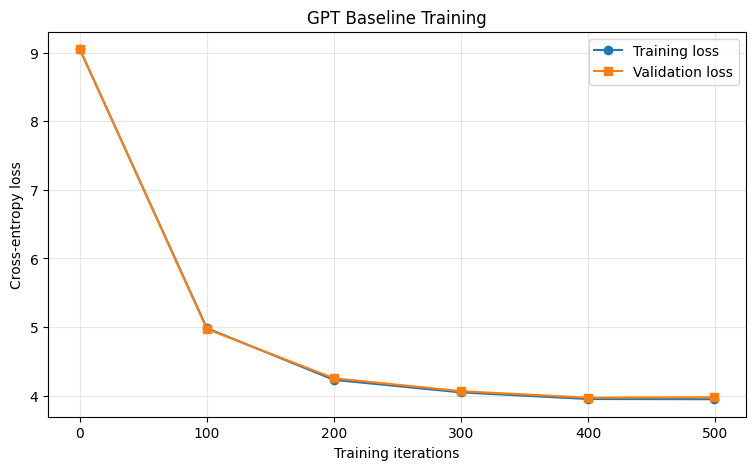

In [24]:
import pandas as pd
import matplotlib.pyplot as plt

history_df = pd.DataFrame(training_history)

plt.figure(figsize=(9, 5))

plt.plot(
    history_df["iteration"],
    history_df["train_loss"],
    marker="o",
    label="Training loss"
)

plt.plot(
    history_df["iteration"],
    history_df["val_loss"],
    marker="s",
    label="Validation loss"
)

plt.xlabel("Training iterations")
plt.ylabel("Cross-entropy loss")
plt.title("GPT Baseline Training")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [25]:
model.eval()

bos_id = tokenizer.token_to_id("[BOS]")
eos_id = tokenizer.token_to_id("[EOS]")

context = torch.tensor(
    [[bos_id]],
    dtype=torch.long,
    device=device
)

generated = model.generate(
    context,
    max_new_tokens=200,
    temperature=0.8
)

generated_ids = generated[0].tolist()

# Remove BOS
if generated_ids[0] == bos_id:
    generated_ids = generated_ids[1:]

# Stop at EOS
if eos_id in generated_ids:
    generated_ids = generated_ids[:generated_ids.index(eos_id)]

print(tokenizer.decode(generated_ids))

 helped it all about the grown. The book were pulled, and the picture in the car. It was nice and shiny by the lake and feeling sorry, daddy.

Her mom found a special. But it. She loved to help up, but he could be so happy that it was so disappear and he said, but they be friends.

The little girl would always too. They saw shoes and deep years old.
The little boy was a little girl loved to be kind!€

The little boy named Timmy was so sorry, "Can you wear you, it's go in a song!" he was going to be came to see and said, "You.


"You are a bit the tree called eras. They needed not tired.
Anna was very sad. They made her mom said. They decided to play with their mom said, "I listened to put on, "I love it."
The story's wish."

Or you


In [26]:

import torch
import torch.nn.functional as F
import time
import math
import os

# ==========================================
# 1. EXPERIMENT CONFIGURATION
# ==========================================

MAX_ITERS = 5000
BATCH_SIZE = 32
BLOCK_SIZE = 256

LEARNING_RATE = 3e-4
WEIGHT_DECAY = 0.1

WARMUP_ITERS = 200
EVAL_INTERVAL = 500
EVAL_ITERS = 50

GRAD_CLIP = 1.0

# ==========================================
# 2. INITIALISE A FRESH MODEL
# ==========================================

model = GPTLanguageModel(
    vocab_size=8000,
    n_embd=256,
    n_layer=4,
    n_head=4,
    block_size=256,
    dropout=0.1
).to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    betas=(0.9, 0.95),
    weight_decay=WEIGHT_DECAY
)

scaler = torch.amp.GradScaler("cuda")

# ==========================================
# 3. LEARNING RATE SCHEDULE
# ==========================================

def get_lr(iteration):
    if iteration < WARMUP_ITERS:
        return LEARNING_RATE * (iteration + 1) / WARMUP_ITERS

    progress = (
        iteration - WARMUP_ITERS
    ) / (MAX_ITERS - WARMUP_ITERS)

    progress = min(progress, 1.0)

    return LEARNING_RATE * 0.5 * (
        1 + math.cos(math.pi * progress)
    )

# ==========================================
# 4. VALIDATION FUNCTION
# ==========================================

@torch.no_grad()
def evaluate_model():
    model.eval()

    results = {}

    for name, data in [
        ("train", train_data),
        ("val", val_data)
    ]:
        losses = []

        for _ in range(EVAL_ITERS):
            x, y = get_batch(data)

            with torch.amp.autocast(
                "cuda",
                dtype=torch.float16
            ):
                _, loss = model(x, y)

            losses.append(loss.item())

        results[name] = sum(losses) / len(losses)

    model.train()
    return results

# ==========================================
# 5. TRAINING
# ==========================================

os.makedirs("checkpoints", exist_ok=True)

training_history_5000 = []

model.train()

torch.cuda.reset_peak_memory_stats()
torch.cuda.synchronize()

start_time = time.time()

for iteration in range(MAX_ITERS):

    # Update learning rate
    lr = get_lr(iteration)

    for param_group in optimizer.param_groups:
        param_group["lr"] = lr

    # Get batch
    xb, yb = get_batch(train_data)

    # Clear gradients
    optimizer.zero_grad(set_to_none=True)

    # Forward pass
    with torch.amp.autocast(
        "cuda",
        dtype=torch.float16
    ):
        logits, loss = model(xb, yb)

    # Backward pass
    scaler.scale(loss).backward()

    scaler.unscale_(optimizer)

    torch.nn.utils.clip_grad_norm_(
        model.parameters(),
        GRAD_CLIP
    )

    scaler.step(optimizer)
    scaler.update()

    # Evaluate periodically
    if iteration % EVAL_INTERVAL == 0 or iteration == MAX_ITERS - 1:

        results = evaluate_model()

        torch.cuda.synchronize()
        elapsed = time.time() - start_time

        record = {
            "iteration": iteration,
            "train_loss": results["train"],
            "val_loss": results["val"],
            "learning_rate": lr,
            "elapsed_seconds": elapsed
        }

        training_history_5000.append(record)

        print(
            f"Step {iteration:5d} | "
            f"Train loss: {results['train']:.4f} | "
            f"Val loss: {results['val']:.4f} | "
            f"LR: {lr:.6f} | "
            f"Time: {elapsed:.1f}s",
            flush=True
        )

# ==========================================
# 6. SAVE CHECKPOINT
# ==========================================

torch.cuda.synchronize()

total_time = time.time() - start_time

peak_memory = (
    torch.cuda.max_memory_allocated() / 1e9
)

checkpoint = {
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "training_history": training_history_5000,
    "config": {
        "vocab_size": 8000,
        "n_embd": 256,
        "n_layer": 4,
        "n_head": 4,
        "block_size": 256,
        "max_iters": MAX_ITERS,
        "batch_size": BATCH_SIZE,
        "learning_rate": LEARNING_RATE
    }
}

torch.save(
    checkpoint,
    "checkpoints/gpt_baseline_5000.pt"
)

print("\n" + "=" * 45)
print("EXTENDED BASELINE COMPLETED")
print("=" * 45)

print("Total training time:", round(total_time, 2), "seconds")
print("Peak GPU memory:", round(peak_memory, 2), "GB")
print("Final training loss:",
      training_history_5000[-1]["train_loss"])
print("Final validation loss:",
      training_history_5000[-1]["val_loss"])
print("Checkpoint saved successfully.")


Step     0 | Train loss: 9.0771 | Val loss: 9.0770 | LR: 0.000001 | Time: 1.6s
Step   500 | Train loss: 3.6739 | Val loss: 3.7139 | LR: 0.000297 | Time: 26.9s
Step  1000 | Train loss: 3.1468 | Val loss: 3.2073 | LR: 0.000280 | Time: 48.4s
Step  1500 | Train loss: 2.8733 | Val loss: 2.9493 | LR: 0.000249 | Time: 70.2s
Step  2000 | Train loss: 2.6778 | Val loss: 2.7922 | LR: 0.000207 | Time: 91.9s
Step  2500 | Train loss: 2.5561 | Val loss: 2.6938 | LR: 0.000160 | Time: 113.6s
Step  3000 | Train loss: 2.4787 | Val loss: 2.6269 | LR: 0.000111 | Time: 135.3s
Step  3500 | Train loss: 2.4035 | Val loss: 2.5831 | LR: 0.000067 | Time: 157.1s
Step  4000 | Train loss: 2.3625 | Val loss: 2.5533 | LR: 0.000031 | Time: 178.8s
Step  4500 | Train loss: 2.3668 | Val loss: 2.5370 | LR: 0.000008 | Time: 200.5s
Step  4999 | Train loss: 2.3643 | Val loss: 2.5115 | LR: 0.000000 | Time: 222.2s

EXTENDED BASELINE COMPLETED
Total training time: 222.19 seconds
Peak GPU memory: 1.41 GB
Final training loss: 2.36

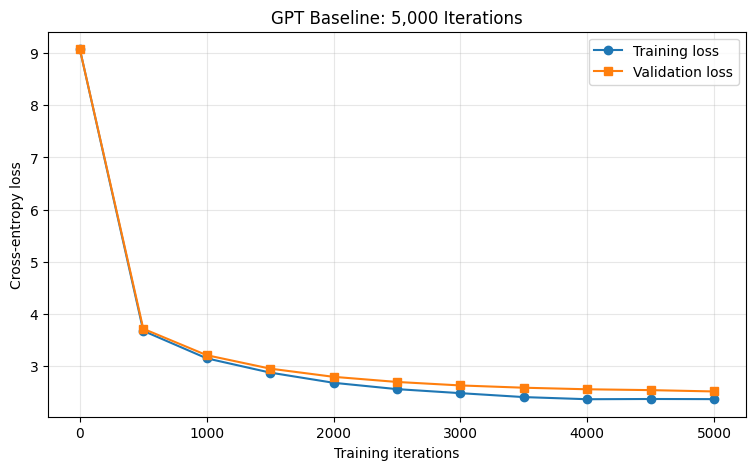

In [27]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame(training_history_5000)

plt.figure(figsize=(9, 5))
plt.plot(df["iteration"], df["train_loss"], marker="o",
         label="Training loss")
plt.plot(df["iteration"], df["val_loss"], marker="s",
         label="Validation loss")

plt.xlabel("Training iterations")
plt.ylabel("Cross-entropy loss")
plt.title("GPT Baseline: 5,000 Iterations")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [28]:

# ==========================================
# GENERATE TEXT FROM TRAINED GPT
# ==========================================

model.eval()

prompts = [
    "Once upon a time, there was a little girl named Lily.",
    "One day, a little boy went to the park.",
    "Anna and Ben wanted to help their mother."
]

for prompt in prompts:

    # Encode natural-language prompt
    prompt_ids = tokenizer.encode(prompt).ids

    context = torch.tensor(
        [prompt_ids],
        dtype=torch.long,
        device=device
    )

    # Generate continuation
    generated = model.generate(
        context,
        max_new_tokens=200,
        temperature=0.8
    )

    generated_ids = generated[0].tolist()

    # Stop at the first EOS token
    if EOS_ID in generated_ids:
        generated_ids = generated_ids[
            :generated_ids.index(EOS_ID)
        ]

    # Decode
    story = tokenizer.decode(
        generated_ids,
        skip_special_tokens=True
    )

    print("=" * 65)
    print("PROMPT:", prompt)
    print("-" * 65)
    print(story)
    print()


PROMPT: Once upon a time, there was a little girl named Lily.
-----------------------------------------------------------------
Once upon a time, there was a little girl named Lily. She loved to play outside in the park with her mommy and daddy. One day, she went to the park with her mommy. She saw a big dog who was small and had a big tail.

Lily said, "Can I catch the dog too?" Her mommy said, "Yes, I can show you how much the dog will get it."

Lily was very excited. She gave the dog some bread and took the dog home. The dog ate the kids and ate them. Lily was so happy and sang a little heart.

PROMPT: One day, a little boy went to the park.
-----------------------------------------------------------------
One day, a little boy went to the park. He saw a big red chair. He opened it and saw a big, brown bird. He wanted to put it on the chair.

The bird flew back to his mom. She picked the jar and put it in his pocket. She carefully glued it under the wall.

He put the shelf back in a

In [29]:

# ==========================================
# EXPERIMENT E2: DATA SCALING
# Dataset preparation
# ==========================================

import numpy as np
from tqdm.auto import tqdm
import os

# Configuration
DATA_SEED = 2026

DATASET_SIZES = [10_000, 50_000, 100_000]
MAX_STORIES = max(DATASET_SIZES)

# ==========================================
# 1. SHUFFLE TRAINING DATA
# ==========================================

# Deterministic shuffle to avoid ordering bias
shuffled_train = train_dataset.shuffle(
    seed=DATA_SEED
).select(range(MAX_STORIES))

print("Selected training stories:", len(shuffled_train))

# ==========================================
# 2. TOKENISE IN CHUNKS
# ==========================================

# Process 10,000 stories at a time
CHUNK_SIZE = 10_000

token_chunks = []

for start in range(0, MAX_STORIES, CHUNK_SIZE):

    end = min(start + CHUNK_SIZE, MAX_STORIES)

    story_ids = []

    for example in tqdm(
        shuffled_train.select(range(start, end)),
        desc=f"Tokenising {start}-{end}"
    ):
        story_ids.extend(
            encode_story(example["text"])
        )

    chunk = np.asarray(
        story_ids,
        dtype=np.uint16
    )

    token_chunks.append(chunk)

    print(
        f"Stories: {end:,} | "
        f"Tokens in chunk: {len(chunk):,}"
    )

# ==========================================
# 3. BUILD NESTED DATASETS
# ==========================================

train_streams = {}

for size in DATASET_SIZES:

    number_of_chunks = size // CHUNK_SIZE

    stream = np.concatenate(
        token_chunks[:number_of_chunks]
    )

    train_streams[size] = torch.from_numpy(
        stream.astype(np.int64)
    )

# ==========================================
# 4. SAVE DATASETS
# ==========================================

os.makedirs("artifacts/data_scaling", exist_ok=True)

for size, data in train_streams.items():

    np.save(
        f"artifacts/data_scaling/train_{size}.npy",
        data.numpy().astype(np.uint16)
    )

    print(
        f"\nD{DATASET_SIZES.index(size)+1}: "
        f"{size:,} stories | "
        f"{len(data):,} tokens | "
        f"{data.numel() * 8 / 1024**2:.2f} MB"
    )

print("\nAll data-scaling datasets prepared!")


Selected training stories: 100000


Tokenising 0-10000:   0%|          | 0/10000 [00:00<?, ?it/s]

Stories: 10,000 | Tokens in chunk: 2,218,441


Tokenising 10000-20000:   0%|          | 0/10000 [00:00<?, ?it/s]

Stories: 20,000 | Tokens in chunk: 2,209,452


Tokenising 20000-30000:   0%|          | 0/10000 [00:00<?, ?it/s]

... (11 outputs left out)

Tokenising 80000-90000:   0%|          | 0/10000 [00:00<?, ?it/s]

Stories: 90,000 | Tokens in chunk: 2,211,917


Tokenising 90000-100000:   0%|          | 0/10000 [00:00<?, ?it/s]

Stories: 100,000 | Tokens in chunk: 2,210,533

D1: 10,000 stories | 2,218,441 tokens | 16.93 MB

D2: 50,000 stories | 11,022,217 tokens | 84.09 MB

D3: 100,000 stories | 22,035,205 tokens | 168.12 MB

All data-scaling datasets prepared!


In [30]:

# =====================================================
# EXPERIMENT E2: DATA SCALING
# Train D1, D2 and D3 under controlled conditions
# =====================================================

import torch
import torch.nn.functional as F
import numpy as np
import pandas as pd
import time
import math
import os
from collections import deque

# -----------------------------------------------------
# 1. EXPERIMENT CONFIGURATION
# -----------------------------------------------------

MAX_ITERS = 5000
BATCH_SIZE = 32
BLOCK_SIZE = 256

LEARNING_RATE = 3e-4
WEIGHT_DECAY = 0.1

WARMUP_ITERS = 200
EVAL_INTERVAL = 500
EVAL_ITERS = 50

GRAD_CLIP = 1.0
SEED = 1234

# Use the same configurations for all datasets
DATA_CONFIGS = {
    "D1_10k": train_streams[10_000],
    "D2_50k": train_streams[50_000],
    "D3_100k": train_streams[100_000]
}

os.makedirs("checkpoints/data_scaling", exist_ok=True)

# -----------------------------------------------------
# 2. FIXED VALIDATION BATCHES
# -----------------------------------------------------

# Every model will be evaluated on exactly the same
# validation batches.

val_generator = torch.Generator()
val_generator.manual_seed(999)

validation_batches = []

for _ in range(EVAL_ITERS):

    ix = torch.randint(
        len(val_data) - BLOCK_SIZE - 1,
        (BATCH_SIZE,),
        generator=val_generator
    )

    offsets = torch.arange(BLOCK_SIZE)

    x = val_data[ix[:, None] + offsets]
    y = val_data[ix[:, None] + offsets + 1]

    validation_batches.append((
        x.to(device),
        y.to(device)
    ))

print("Fixed validation batches prepared:", len(validation_batches))

# -----------------------------------------------------
# 3. HELPER FUNCTIONS
# -----------------------------------------------------

def sample_training_batch(data, generator):

    ix = torch.randint(
        len(data) - BLOCK_SIZE - 1,
        (BATCH_SIZE,),
        generator=generator
    )

    offsets = torch.arange(BLOCK_SIZE)

    x = data[ix[:, None] + offsets]
    y = data[ix[:, None] + offsets + 1]

    return x.to(device), y.to(device)


def get_learning_rate(iteration):

    if iteration < WARMUP_ITERS:
        return LEARNING_RATE * (
            iteration + 1
        ) / WARMUP_ITERS

    progress = (
        iteration - WARMUP_ITERS
    ) / (MAX_ITERS - WARMUP_ITERS)

    progress = min(progress, 1.0)

    return LEARNING_RATE * 0.5 * (
        1 + math.cos(math.pi * progress)
    )


@torch.no_grad()
def evaluate_validation(model):

    model.eval()

    losses = []

    for x, y in validation_batches:

        with torch.amp.autocast(
            "cuda",
            dtype=torch.float16
        ):
            _, loss = model(x, y)

        losses.append(loss.item())

    model.train()

    return float(np.mean(losses))


# -----------------------------------------------------
# 4. TRAIN ALL THREE MODELS
# -----------------------------------------------------

all_results = {}
summary_results = []

for experiment_name, training_data in DATA_CONFIGS.items():

    print("\n" + "=" * 60)
    print("STARTING:", experiment_name)
    print("Training tokens:", len(training_data))
    print("=" * 60)

    # Identical initialisation seed for each model
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

    # Fresh model
    model = GPTLanguageModel(
        vocab_size=8000,
        n_embd=256,
        n_layer=4,
        n_head=4,
        block_size=256,
        dropout=0.1
    ).to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        betas=(0.9, 0.95),
        weight_decay=WEIGHT_DECAY
    )

    scaler = torch.amp.GradScaler("cuda")

    # Independent but identically seeded data sampler
    train_generator = torch.Generator()
    train_generator.manual_seed(SEED + 1)

    model.train()

    torch.cuda.reset_peak_memory_stats()
    torch.cuda.synchronize()

    start_time = time.time()

    history = []
    recent_losses = deque(maxlen=100)

    # -------------------------------------------------
    # TRAINING LOOP
    # -------------------------------------------------

    for iteration in range(MAX_ITERS):

        lr = get_learning_rate(iteration)

        for param_group in optimizer.param_groups:
            param_group["lr"] = lr

        xb, yb = sample_training_batch(
            training_data,
            train_generator
        )

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            "cuda",
            dtype=torch.float16
        ):
            logits, loss = model(xb, yb)

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            GRAD_CLIP
        )

        scaler.step(optimizer)
        scaler.update()

        recent_losses.append(loss.item())

        # -------------------------------------------------
        # PERIODIC EVALUATION
        # -------------------------------------------------

        if (
            iteration % EVAL_INTERVAL == 0
            or iteration == MAX_ITERS - 1
        ):

            val_loss = evaluate_validation(model)

            torch.cuda.synchronize()

            elapsed = time.time() - start_time

            train_loss = float(np.mean(recent_losses))

            record = {
                "iteration": iteration,
                "train_loss": train_loss,
                "val_loss": val_loss,
                "learning_rate": lr,
                "elapsed_seconds": elapsed
            }

            history.append(record)

            print(
                f"{experiment_name} | "
                f"Step {iteration:5d} | "
                f"Train: {train_loss:.4f} | "
                f"Val: {val_loss:.4f} | "
                f"Time: {elapsed:.1f}s",
                flush=True
            )

    # -------------------------------------------------
    # SAVE RESULTS
    # -------------------------------------------------

    torch.cuda.synchronize()

    total_time = time.time() - start_time

    peak_memory = (
        torch.cuda.max_memory_allocated() / 1e9
    )

    final_val_loss = history[-1]["val_loss"]

    # Save individual model checkpoint
    checkpoint = {
        "model_state_dict": model.state_dict(),
        "config": {
            "dataset": experiment_name,
            "training_tokens": len(training_data),
            "max_iters": MAX_ITERS,
            "batch_size": BATCH_SIZE,
            "block_size": BLOCK_SIZE,
            "seed": SEED
        },
        "history": history
    }

    torch.save(
        checkpoint,
        f"checkpoints/data_scaling/{experiment_name}.pt"
    )

    all_results[experiment_name] = history

    summary_results.append({
        "Dataset": experiment_name,
        "Training tokens": len(training_data),
        "Final train loss": history[-1]["train_loss"],
        "Final val loss": final_val_loss,
        "Val perplexity": math.exp(final_val_loss),
        "Training time (s)": total_time,
        "Peak GPU memory (GB)": peak_memory
    })

    print("\nCompleted:", experiment_name)
    print("Final validation loss:", final_val_loss)
    print("Training time:", round(total_time, 2), "seconds")
    print("Peak memory:", round(peak_memory, 2), "GB")

    del model, optimizer, scaler
    torch.cuda.empty_cache()

# -----------------------------------------------------
# 5. FINAL COMPARISON TABLE
# -----------------------------------------------------

results_df = pd.DataFrame(summary_results)

print("\n" + "=" * 70)
print("EXPERIMENT E2: FINAL RESULTS")
print("=" * 70)

display(results_df)

results_df.to_csv(
    "artifacts/data_scaling_results.csv",
    index=False
)

print("Results saved successfully.")


Fixed validation batches prepared: 50

STARTING: D1_10k
Training tokens: 2218441
D1_10k | Step     0 | Train: 9.0333 | Val: 9.0309 | Time: 0.8s
D1_10k | Step   500 | Train: 3.8138 | Val: 3.6996 | Time: 24.8s
D1_10k | Step  1000 | Train: 3.2746 | Val: 3.2086 | Time: 45.8s
D1_10k | Step  1500 | Train: 3.0065 | Val: 2.9700 | Time: 66.3s
D1_10k | Step  2000 | Train: 2.8323 | Val: 2.8223 | Time: 87.3s
D1_10k | Step  2500 | Train: 2.7315 | Val: 2.7263 | Time: 108.4s
D1_10k | Step  3000 | Train: 2.6260 | Val: 2.6531 | Time: 129.3s
D1_10k | Step  3500 | Train: 2.5840 | Val: 2.6069 | Time: 150.3s
D1_10k | Step  4000 | Train: 2.5502 | Val: 2.5796 | Time: 171.3s
D1_10k | Step  4500 | Train: 2.5355 | Val: 2.5665 | Time: 192.3s
D1_10k | Step  4999 | Train: 2.5298 | Val: 2.5638 | Time: 213.3s

Completed: D1_10k
Final validation loss: 2.5638455963134765
Training time: 213.26 seconds
Peak memory: 1.48 GB

STARTING: D2_50k
Training tokens: 11022217
D2_50k | Step     0 | Train: 9.0286 | Val: 9.0309 | Ti

,Dataset,Training tokens,Final train loss,Final val loss,Val perplexity,Training time (s),Peak GPU memory (GB)
0,D1_10k,2218441,2.529778,2.563846,12.985659,213.263371,1.484341
1,D2_50k,11022217,2.613901,2.517596,12.398760,210.713300,1.442812
2,D3_100k,22035205,2.625996,2.508211,12.282935,210.751632,1.442714


Results saved successfully.


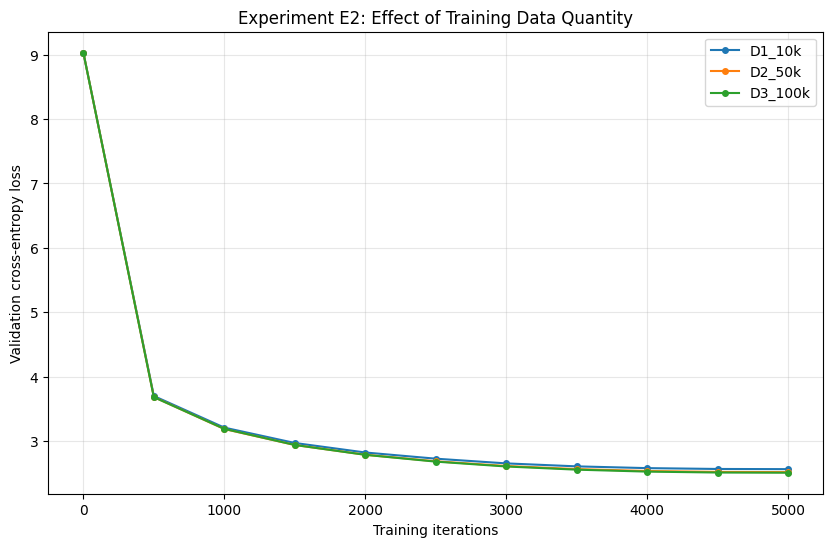

In [31]:
import matplotlib.pyplot as plt
import pandas as pd

# Plot validation loss throughout training
plt.figure(figsize=(10, 6))

for name, history in all_results.items():

    df = pd.DataFrame(history)

    plt.plot(
        df["iteration"],
        df["val_loss"],
        marker="o",
        markersize=4,
        label=name
    )

plt.xlabel("Training iterations")
plt.ylabel("Validation cross-entropy loss")
plt.title("Experiment E2: Effect of Training Data Quantity")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(
    "artifacts/data_scaling_learning_curves.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

In [32]:

# =====================================================
# EXPERIMENT E2 REPLICATION
# Three datasets x three random seeds
# =====================================================

import torch
import numpy as np
import pandas as pd
import time
import math
import os
import gc
from tqdm.auto import tqdm

# -----------------------------------------------------
# 1. CONFIGURATION
# -----------------------------------------------------

MAX_ITERS = 5000
BATCH_SIZE = 32
BLOCK_SIZE = 256

LEARNING_RATE = 3e-4
WEIGHT_DECAY = 0.1

WARMUP_ITERS = 200
EVAL_INTERVAL = 500
EVAL_ITERS = 50

GRAD_CLIP = 1.0

SEEDS = [2027, 2028]

DATA_CONFIGS = {
    "D1_10k": train_streams[10_000],
    "D2_50k": train_streams[50_000],
    "D3_100k": train_streams[100_000]
}

os.makedirs("checkpoints/data_scaling", exist_ok=True)
os.makedirs("artifacts/data_scaling", exist_ok=True)

# -----------------------------------------------------
# 2. FIXED VALIDATION BATCHES
# -----------------------------------------------------

# Recreate the same validation batches used in E2.

val_generator = torch.Generator()
val_generator.manual_seed(999)

validation_batches = []

for _ in range(EVAL_ITERS):

    ix = torch.randint(
        len(val_data) - BLOCK_SIZE - 1,
        (BATCH_SIZE,),
        generator=val_generator
    )

    offsets = torch.arange(BLOCK_SIZE)

    x = val_data[ix[:, None] + offsets]
    y = val_data[ix[:, None] + offsets + 1]

    validation_batches.append((
        x.to(device),
        y.to(device)
    ))

print("Fixed validation batches:", len(validation_batches))

# -----------------------------------------------------
# 3. HELPER FUNCTIONS
# -----------------------------------------------------

def get_lr_rep(iteration):

    if iteration < WARMUP_ITERS:
        return LEARNING_RATE * (
            iteration + 1
        ) / WARMUP_ITERS

    progress = (
        iteration - WARMUP_ITERS
    ) / (MAX_ITERS - WARMUP_ITERS)

    progress = min(progress, 1.0)

    return LEARNING_RATE * 0.5 * (
        1 + math.cos(math.pi * progress)
    )


def sample_batch_rep(data, generator):

    ix = torch.randint(
        len(data) - BLOCK_SIZE - 1,
        (BATCH_SIZE,),
        generator=generator
    )

    offsets = torch.arange(BLOCK_SIZE)

    x = data[ix[:, None] + offsets]
    y = data[ix[:, None] + offsets + 1]

    return x.to(device), y.to(device)


@torch.no_grad()
def evaluate_rep(model):

    model.eval()

    losses = []

    for x, y in validation_batches:

        with torch.amp.autocast(
            "cuda",
            dtype=torch.float16
        ):
            _, loss = model(x, y)

        losses.append(loss.item())

    model.train()

    return float(np.mean(losses))


# -----------------------------------------------------
# 4. RUN REPLICATION EXPERIMENTS
# -----------------------------------------------------

replication_results = {}

replication_summary = []

for experiment_name, training_data in DATA_CONFIGS.items():

    for seed in SEEDS:

        run_name = f"{experiment_name}_seed{seed}"

        print("\n" + "=" * 65)
        print("STARTING:", run_name)
        print("Training tokens:", len(training_data))
        print("=" * 65)

        # Reproducible initialisation
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        np.random.seed(seed)

        # Fresh model
        model = GPTLanguageModel(
            vocab_size=8000,
            n_embd=256,
            n_layer=4,
            n_head=4,
            block_size=256,
            dropout=0.1
        ).to(device)

        optimizer = torch.optim.AdamW(
            model.parameters(),
            lr=LEARNING_RATE,
            betas=(0.9, 0.95),
            weight_decay=WEIGHT_DECAY
        )

        scaler = torch.amp.GradScaler("cuda")

        # Independent reproducible batch sampler
        train_generator = torch.Generator()
        train_generator.manual_seed(seed + 1)

        history = []
        recent_losses = []

        model.train()

        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()

        start_time = time.time()

        # -------------------------------------------------
        # TRAINING LOOP
        # -------------------------------------------------

        for iteration in range(MAX_ITERS):

            lr = get_lr_rep(iteration)

            for param_group in optimizer.param_groups:
                param_group["lr"] = lr

            xb, yb = sample_batch_rep(
                training_data,
                train_generator
            )

            optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast(
                "cuda",
                dtype=torch.float16
            ):
                logits, loss = model(xb, yb)

            scaler.scale(loss).backward()

            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                GRAD_CLIP
            )

            scaler.step(optimizer)
            scaler.update()

            recent_losses.append(loss.item())

            if (
                iteration % EVAL_INTERVAL == 0
                or iteration == MAX_ITERS - 1
            ):

                val_loss = evaluate_rep(model)

                torch.cuda.synchronize()
                elapsed = time.time() - start_time

                train_loss = float(
                    np.mean(recent_losses[-100:])
                )

                history.append({
                    "iteration": iteration,
                    "train_loss": train_loss,
                    "val_loss": val_loss,
                    "learning_rate": lr,
                    "elapsed_seconds": elapsed
                })

                print(
                    f"{run_name} | "
                    f"Step {iteration:5d} | "
                    f"Train: {train_loss:.4f} | "
                    f"Val: {val_loss:.4f} | "
                    f"Time: {elapsed:.1f}s",
                    flush=True
                )

        # -------------------------------------------------
        # SAVE CHECKPOINT AND RESULTS
        # -------------------------------------------------

        torch.cuda.synchronize()

        total_time = time.time() - start_time

        peak_memory = (
            torch.cuda.max_memory_allocated() / 1e9
        )

        final_train = history[-1]["train_loss"]
        final_val = history[-1]["val_loss"]

        checkpoint = {
            "model_state_dict": model.state_dict(),
            "config": {
                "dataset": experiment_name,
                "seed": seed,
                "training_tokens": len(training_data),
                "max_iters": MAX_ITERS,
                "batch_size": BATCH_SIZE,
                "block_size": BLOCK_SIZE
            },
            "history": history
        }

        torch.save(
            checkpoint,
            f"checkpoints/data_scaling/{run_name}.pt"
        )

        replication_results[run_name] = history

        replication_summary.append({
            "Dataset": experiment_name,
            "Seed": seed,
            "Training tokens": len(training_data),
            "Final train loss": final_train,
            "Final val loss": final_val,
            "Val perplexity": math.exp(final_val),
            "Training time (s)": total_time,
            "Peak GPU memory (GB)": peak_memory
        })

        print("\nCompleted:", run_name)
        print("Validation loss:", round(final_val, 5))
        print("Training time:", round(total_time, 2), "seconds")

        # Release resources
        del model, optimizer, scaler
        gc.collect()
        torch.cuda.empty_cache()

        # Save results after EVERY run
        pd.DataFrame(replication_summary).to_csv(
            "artifacts/data_scaling/replication_results.csv",
            index=False
        )

# -----------------------------------------------------
# 5. COMBINE WITH ORIGINAL SEED 1234
# -----------------------------------------------------

original_rows = []

for name, history in all_results.items():

    final = history[-1]

    original_rows.append({
        "Dataset": name,
        "Seed": 1234,
        "Training tokens": DATA_CONFIGS[name].numel(),
        "Final train loss": final["train_loss"],
        "Final val loss": final["val_loss"],
        "Val perplexity": math.exp(final["val_loss"])
    })

original_df = pd.DataFrame(original_rows)

replication_df = pd.DataFrame(replication_summary)

combined_df = pd.concat(
    [
        original_df,
        replication_df
    ],
    ignore_index=True
)

print("\n" + "=" * 65)
print("ALL EXPERIMENTAL RUNS")
print("=" * 65)

display(combined_df)

# -----------------------------------------------------
# 6. MEAN AND STANDARD DEVIATION
# -----------------------------------------------------

summary_df = combined_df.groupby("Dataset").agg(
    mean_val_loss=("Final val loss", "mean"),
    std_val_loss=("Final val loss", "std"),
    mean_perplexity=("Val perplexity", "mean"),
    std_perplexity=("Val perplexity", "std"),
    mean_train_loss=("Final train loss", "mean"),
    mean_training_time=("Training time (s)", "mean")
).reset_index()

print("\n" + "=" * 65)
print("E2 REPLICATION: MEAN +/- STANDARD DEVIATION")
print("=" * 65)

display(summary_df)

combined_df.to_csv(
    "artifacts/data_scaling/all_runs.csv",
    index=False
)

summary_df.to_csv(
    "artifacts/data_scaling/summary_statistics.csv",
    index=False
)

print("\nAll replication experiments completed!")
print("Results and checkpoints saved.")


Fixed validation batches: 50

STARTING: D1_10k_seed2027
Training tokens: 2218441
D1_10k_seed2027 | Step     0 | Train: 9.0471 | Val: 9.0392 | Time: 1.2s
D1_10k_seed2027 | Step   500 | Train: 3.8146 | Val: 3.6964 | Time: 25.0s
D1_10k_seed2027 | Step  1000 | Train: 3.2666 | Val: 3.2014 | Time: 46.4s
D1_10k_seed2027 | Step  1500 | Train: 2.9921 | Val: 2.9566 | Time: 67.0s
D1_10k_seed2027 | Step  2000 | Train: 2.8159 | Val: 2.8056 | Time: 88.0s
D1_10k_seed2027 | Step  2500 | Train: 2.7147 | Val: 2.7088 | Time: 109.0s
D1_10k_seed2027 | Step  3000 | Train: 2.6185 | Val: 2.6384 | Time: 130.0s
D1_10k_seed2027 | Step  3500 | Train: 2.5663 | Val: 2.5937 | Time: 151.0s
D1_10k_seed2027 | Step  4000 | Train: 2.5355 | Val: 2.5672 | Time: 172.0s
D1_10k_seed2027 | Step  4500 | Train: 2.5195 | Val: 2.5543 | Time: 193.0s
D1_10k_seed2027 | Step  4999 | Train: 2.5095 | Val: 2.5511 | Time: 214.0s

Completed: D1_10k_seed2027
Validation loss: 2.55112
Training time: 213.96 seconds

STARTING: D1_10k_seed2028
T

,Dataset,Seed,Training tokens,Final train loss,Final val loss,Val perplexity,Training time (s),Peak GPU memory (GB)
0,D1_10k,1234,2218441,2.529778,2.563846,12.985659,NaN,NaN
1,D2_50k,1234,11022217,2.613901,2.517596,12.398760,NaN,NaN
2,D3_100k,1234,22035205,2.625996,2.508211,12.282935,NaN,NaN
3,D1_10k,2027,2218441,2.509523,2.551119,12.821447,213.957085,1.442419
4,D1_10k,2028,2218441,2.525023,2.551473,12.825983,210.741449,1.443729
5,D2_50k,2027,11022217,2.602224,2.516662,12.387184,210.758042,1.443271
6,D2_50k,2028,11022217,2.616635,2.513637,12.349760,210.774613,1.443271
7,D3_100k,2027,22035205,2.622811,2.512237,12.332489,210.776396,1.443271
8,D3_100k,2028,22035205,2.638808,2.524622,12.486170,210.772223,1.443271



E2 REPLICATION: MEAN +/- STANDARD DEVIATION


,Dataset,mean_val_loss,std_val_loss,mean_perplexity,std_perplexity,mean_train_loss,mean_training_time
0,D1_10k,2.555479,0.007248,12.877696,0.093526,2.521441,212.349267
1,D2_50k,2.515965,0.002070,12.378568,0.025611,2.610920,210.766327
2,D3_100k,2.515023,0.008553,12.367198,0.105970,2.629205,210.774309



All replication experiments completed!
Results and checkpoints saved.


In [33]:

# =====================================================
# EXPERIMENT E3: MODEL SCALING UNDER FIXED TIME
# =====================================================

import torch
import numpy as np
import pandas as pd
import time
import math
import os
import gc

# -----------------------------------------------------
# 1. CONFIGURATION
# -----------------------------------------------------

TIME_BUDGET = 150       # seconds per model
BATCH_SIZE = 32
BLOCK_SIZE = 256

LEARNING_RATE = 3e-4
WEIGHT_DECAY = 0.1
WARMUP_STEPS = 100
EVAL_INTERVAL = 500
EVAL_ITERS = 50
GRAD_CLIP = 1.0

SEED = 1234

# All models use the same training dataset
training_data = train_streams[100_000]

# Model configurations
MODEL_CONFIGS = {
    "Small_5M": {
        "n_embd": 256,
        "n_layer": 4,
        "n_head": 4
    },
    "Medium_14M": {
        "n_embd": 384,
        "n_layer": 6,
        "n_head": 6
    },
    "Large_30M": {
        "n_embd": 512,
        "n_layer": 8,
        "n_head": 8
    }
}

os.makedirs("checkpoints/model_scaling", exist_ok=True)
os.makedirs("artifacts/model_scaling", exist_ok=True)

# -----------------------------------------------------
# 2. FIXED VALIDATION BATCHES
# -----------------------------------------------------

# Use the same validation batches as E2 replication.
# If validation_batches already exists, retain it.

assert len(validation_batches) == EVAL_ITERS

# -----------------------------------------------------
# 3. HELPER FUNCTIONS
# -----------------------------------------------------

def evaluate_model_scaling(model):

    model.eval()
    losses = []

    with torch.no_grad():

        for x, y in validation_batches:

            with torch.amp.autocast(
                "cuda",
                dtype=torch.float16
            ):
                _, loss = model(x, y)

            losses.append(loss.item())

    model.train()

    return float(np.mean(losses))


# -----------------------------------------------------
# 4. TRAIN THREE MODEL SIZES
# -----------------------------------------------------

scaling_histories = {}
scaling_summary = []

for model_name, config in MODEL_CONFIGS.items():

    print("\n" + "=" * 65)
    print("STARTING:", model_name)
    print("=" * 65)

    # Reproducible initialisation
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)
    np.random.seed(SEED)

    model = GPTLanguageModel(
        vocab_size=8000,
        n_embd=config["n_embd"],
        n_layer=config["n_layer"],
        n_head=config["n_head"],
        block_size=BLOCK_SIZE,
        dropout=0.1
    ).to(device)

    n_params = sum(
        p.numel() for p in model.parameters()
    )

    print("Parameters:", f"{n_params:,}")

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        betas=(0.9, 0.95),
        weight_decay=WEIGHT_DECAY
    )

    scaler = torch.amp.GradScaler("cuda")

    train_generator = torch.Generator()
    train_generator.manual_seed(SEED + 1)

    model.train()

    torch.cuda.reset_peak_memory_stats()
    torch.cuda.synchronize()

    start_time = time.perf_counter()

    history = []
    iteration = 0
    recent_losses = []

    # -------------------------------------------------
    # FIXED WALL-CLOCK TRAINING BUDGET
    # -------------------------------------------------

    while time.perf_counter() - start_time < TIME_BUDGET:

        # Linear warmup, then constant learning rate
        if iteration < WARMUP_STEPS:
            lr = LEARNING_RATE * (
                iteration + 1
            ) / WARMUP_STEPS
        else:
            lr = LEARNING_RATE

        for group in optimizer.param_groups:
            group["lr"] = lr

        xb, yb = sample_batch_rep(
            training_data,
            train_generator
        )

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            "cuda",
            dtype=torch.float16
        ):
            logits, loss = model(xb, yb)

        scaler.scale(loss).backward()

        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            GRAD_CLIP
        )

        scaler.step(optimizer)
        scaler.update()

        recent_losses.append(loss.item())
        iteration += 1

        # Periodic validation
        if iteration % EVAL_INTERVAL == 0:

            val_loss = evaluate_model_scaling(model)

            torch.cuda.synchronize()

            elapsed = time.perf_counter() - start_time

            record = {
                "iteration": iteration,
                "train_loss": float(
                    np.mean(recent_losses[-100:])
                ),
                "val_loss": val_loss,
                "elapsed_seconds": elapsed
            }

            history.append(record)

            print(
                f"{model_name} | "
                f"Step {iteration:5d} | "
                f"Train: {record['train_loss']:.4f} | "
                f"Val: {val_loss:.4f} | "
                f"Time: {elapsed:.1f}s",
                flush=True
            )

    # -------------------------------------------------
    # FINAL EVALUATION
    # -------------------------------------------------

    final_val_loss = evaluate_model_scaling(model)

    torch.cuda.synchronize()

    total_time = time.perf_counter() - start_time

    peak_memory = (
        torch.cuda.max_memory_allocated() / 1e9
    )

    final_train_loss = float(
        np.mean(recent_losses[-100:])
    )

    # Record final result
    final_record = {
        "iteration": iteration,
        "train_loss": final_train_loss,
        "val_loss": final_val_loss,
        "elapsed_seconds": total_time
    }

    history.append(final_record)

    scaling_histories[model_name] = history

    # -------------------------------------------------
    # SAVE CHECKPOINT
    # -------------------------------------------------

    torch.save({
        "model_state_dict": model.state_dict(),
        "config": config,
        "parameters": n_params,
        "iterations": iteration,
        "training_tokens": len(training_data),
        "validation_loss": final_val_loss,
        "seed": SEED,
        "history": history
    }, f"checkpoints/model_scaling/{model_name}.pt")

    scaling_summary.append({
        "Model": model_name,
        "Parameters": n_params,
        "Iterations": iteration,
        "Tokens processed": iteration * BATCH_SIZE * BLOCK_SIZE,
        "Final train loss": final_train_loss,
        "Final val loss": final_val_loss,
        "Val perplexity": math.exp(final_val_loss),
        "Training time (s)": total_time,
        "Peak GPU memory (GB)": peak_memory
    })

    print("\nCompleted:", model_name)
    print("Iterations:", iteration)
    print("Validation loss:", round(final_val_loss, 5))
    print("Training time:", round(total_time, 2), "seconds")
    print("Peak memory:", round(peak_memory, 2), "GB")

    del model, optimizer, scaler
    gc.collect()
    torch.cuda.empty_cache()

    # Save results after each model
    pd.DataFrame(scaling_summary).to_csv(
        "artifacts/model_scaling/results.csv",
        index=False
    )

# -----------------------------------------------------
# 5. FINAL COMPARISON
# -----------------------------------------------------

scaling_df = pd.DataFrame(scaling_summary)

print("\n" + "=" * 70)
print("EXPERIMENT E3: MODEL SCALING RESULTS")
print("=" * 70)

display(scaling_df)

scaling_df.to_csv(
    "artifacts/model_scaling/results.csv",
    index=False
)

print("\nE3 completed. Checkpoints and results saved.")



STARTING: Small_5M
Parameters: 5,273,088
Small_5M | Step   500 | Train: 3.7694 | Val: 3.6215 | Time: 22.9s
Small_5M | Step  1000 | Train: 3.2800 | Val: 3.1522 | Time: 44.4s
Small_5M | Step  1500 | Train: 3.0208 | Val: 2.9050 | Time: 65.4s
Small_5M | Step  2000 | Train: 2.8606 | Val: 2.7429 | Time: 86.3s
Small_5M | Step  2500 | Train: 2.7492 | Val: 2.6264 | Time: 107.4s
Small_5M | Step  3000 | Train: 2.6638 | Val: 2.5415 | Time: 128.4s
Small_5M | Step  3500 | Train: 2.5925 | Val: 2.4708 | Time: 149.3s

Completed: Small_5M
Iterations: 3517
Validation loss: 2.4671
Training time: 150.73 seconds
Peak memory: 1.46 GB

STARTING: Medium_14M
Parameters: 13,817,856
Medium_14M | Step   500 | Train: 3.5404 | Val: 3.3954 | Time: 45.9s
Medium_14M | Step  1000 | Train: 3.0285 | Val: 2.9089 | Time: 91.8s
Medium_14M | Step  1500 | Train: 2.7566 | Val: 2.6563 | Time: 137.3s

Completed: Medium_14M
Iterations: 1645
Validation loss: 2.60919
Training time: 151.52 seconds
Peak memory: 2.0 GB

STARTING: Larg

,Model,Parameters,Iterations,Tokens processed,Final train loss,Final val loss,Val perplexity,Training time (s),Peak GPU memory (GB)
0,Small_5M,5273088,3517,28811264,2.583815,2.467100,11.788212,150.734464,1.463806
1,Medium_14M,13817856,1645,13475840,2.696390,2.609190,13.588042,151.515960,2.000912
2,Large_30M,29447168,903,7397376,2.958713,2.840117,17.117772,152.697794,2.788774



E3 completed. Checkpoints and results saved.
